In [1]:
%reload_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from read_waveforms import plot_waveform
from spe_fit_funcs import fit_spe
from dataset_catalog import load_catalog
from spe_fit_funcs import plot_region_waveforms
from read_waveforms import load_waveforms
catalog = load_catalog()

In [4]:
catalog.columns.values

<StringArray>
[                     'path',                      'name',
                   'trigger',                'voltage_kV',
                   'started',                     'ended',
                'duration_s',                    'events',
                  'baseline',              'baseline_rms',
 'baseline_within_tolerance',                 'threshold',
             'threshold_adc',                   'channel',
        'channel_thresholds',                  'polarity',
             'dynamic_range',            'target_percent',
                       'dac',              'channel_mask',
          'enabled_channels',             'record_length',
       'pre_trigger_samples',      'post_trigger_samples',
          'sample_period_ns',        'waveforms_per_file',
                   'n_files',               'stop_reason',
                  'io_level',                  'majority',
     'coincidence_window_ns',                'pair_logic',
               'board_model',             

In [5]:
catalog[catalog['trigger'] == 'external']

,path,name,trigger,voltage_kV,started,ended,duration_s,events,baseline,baseline_rms,...,waveforms_per_file,n_files,stop_reason,io_level,majority,coincidence_window_ns,pair_logic,board_model,board_serial,adc_bits
1,/home/xenon/icdaq/ICXe-DAQ/data/externa_trigge...,externa_trigger,external,NaN,2026-10-26 17:02:26+00:00,2026-10-26 17:02:26+00:00,0.0,10,7828.486467,1336.712340,...,100,1,max_events,TTL,NaN,NaN,NaN,V1730SB,30176,14
20,/home/xenon/icdaq/ICXe-DAQ/data/PMT_1_0kV_2vpp...,PMT_1_0kV_2vpp_ext_1_38V_80nsLED,external,1.0,2026-10-27 15:45:45+00:00,2026-10-27 15:52:44+00:00,419.0,1000000,13922.140379,2.699674,...,50000,20,max_events,TTL,NaN,NaN,NaN,V1730SB,30176,14
25,/home/xenon/icdaq/ICXe-DAQ/data/PMT_1_4kV_2vpp...,PMT_1_4kV_2vpp_ext_2_68V_100nsLED,external,1.4,2026-10-27 18:03:22+00:00,2026-10-27 18:14:29+00:00,667.0,2000000,13922.399852,2.701307,...,50000,40,max_events,TTL,NaN,NaN,NaN,V1730SB,30176,14
26,/home/xenon/icdaq/ICXe-DAQ/data/PMT_1_4kV_2vpp...,PMT_1_4kV_2vpp_ext_2_68V_100nsLED,external,1.4,2026-10-27 18:32:09+00:00,2026-10-27 18:43:16+00:00,667.0,2000000,13922.263041,2.783609,...,50000,40,max_events,TTL,NaN,NaN,NaN,V1730SB,30176,14


In [84]:
# find waveform file
import glob

files_atbase = sorted(glob.glob('../data/PMT_1_4kV_2vpp_ext_*1803*/wf_*.bin', recursive=True))
print(len(files_atbase))
files_at4_5m = sorted(glob.glob('../data/PMT_1_4kV_2vpp_ext_*1832*/wf_*.bin', recursive=True))
print(len(files_at4_5m))
# for path in files:
#     print(path)

40
40


In [85]:
from read_waveforms import load_waveforms
def load_waveforms_from_files(files):
    loaded = [load_waveforms(path) for path in sorted(files)]
    waveforms = np.concatenate([w for w, _ in loaded], axis=0)
    headers = {
        key: np.concatenate([h[key] for _, h in loaded])
        for key in loaded[0][1]
    }
    return waveforms, headers

waveforms_atbase, headers_atbase = load_waveforms_from_files(files_atbase)
print(waveforms_atbase.shape)
waveforms_at4_5m, headers_at4_5m = load_waveforms_from_files(files_at4_5m)
print(waveforms_at4_5m.shape)

(2000000, 2, 1020)
(2000000, 2, 1020)


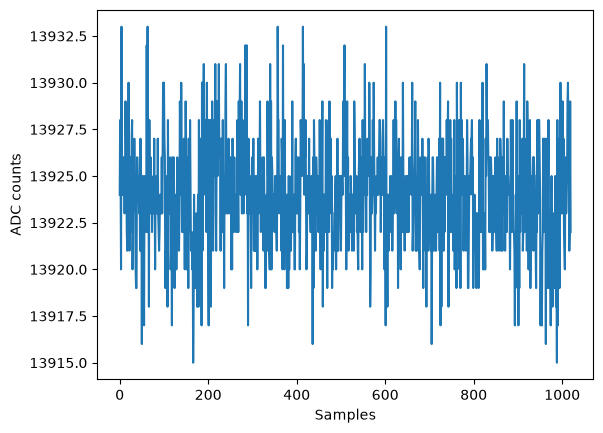

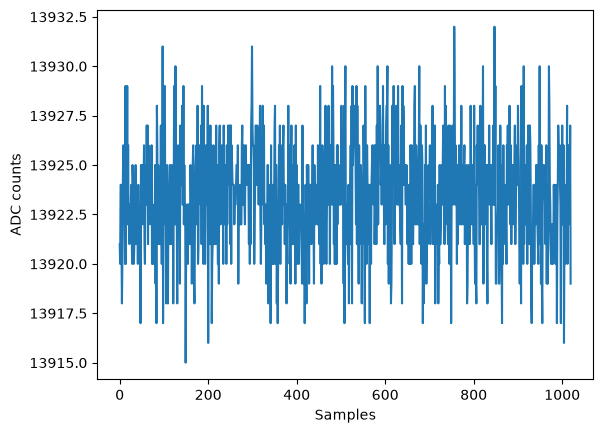

In [86]:
plot_waveform(waveforms_atbase[44123,0,:], full_range=False)
plot_waveform(waveforms_at4_5m[44123,0,:], full_range=False)

In [99]:
def get_spectra_mv(waveforms):
    wfs = waveforms[:,0,:]
    baselines = np.mean(wfs[:,:200], axis = 1)
    wfs_mv = -1 * ((wfs - baselines[:, None]) * 2 * 1000 )/ (2**14)
    amplitudes_mv = np.max(wfs_mv[:,:], axis = 1)
    dt = 2
    sum_waveform_LED = np.sum(wfs_mv[:,580:620], axis=1) * dt
    sum_waveform_noise = np.sum(wfs_mv[:,80:120], axis=1) * dt
    return amplitudes_mv, sum_waveform_LED, sum_waveform_noise

# amplitudes = -(np.min(wfs[:,:], axis = 1) - baselines)

In [101]:
amplitudes_mv_atbase, sum_waveform_LED_atbase, sum_waveform_noise_atbase = get_spectra_mv(waveforms_atbase)
amplitudes_mv_at4_5m, sum_waveform_LED_at4_5m, sum_waveform_noise_at4_5m = get_spectra_mv(waveforms_at4_5m)

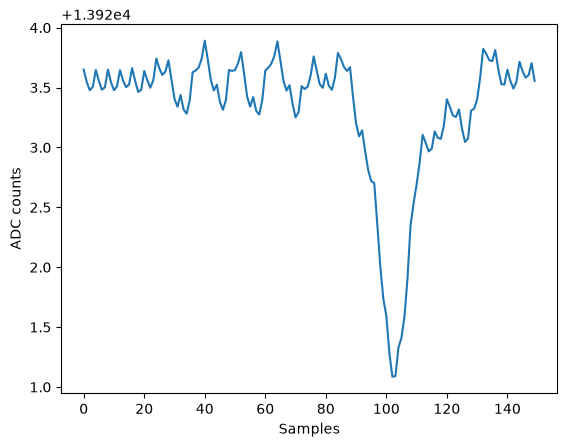

In [28]:
#plot the average waveform
avg_waveform = np.mean(wfs[:,:], axis=0)
plot_waveform(avg_waveform[500:650], full_range=False)

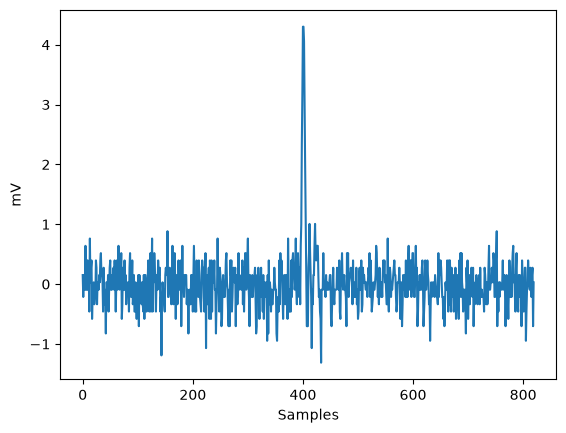

In [98]:
#plot_waveform(wfs_mv[441112,500:650], full_range=False)
plot_waveform(wfs_mv[3333,200:], full_range=False, ylabel='mV')

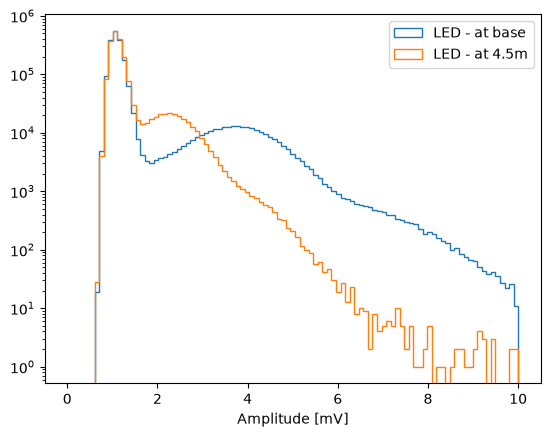

In [102]:
plt.hist(amplitudes_mv_atbase, bins=np.linspace(0, 10, 100), histtype='step', label='LED - at base')
plt.hist(amplitudes_mv_at4_5m, bins=np.linspace(0, 10, 100), histtype='step', label='LED - at 4.5m')
plt.legend()
plt.yscale('log')
plt.xlabel('Amplitude [mV]')
plt.show()

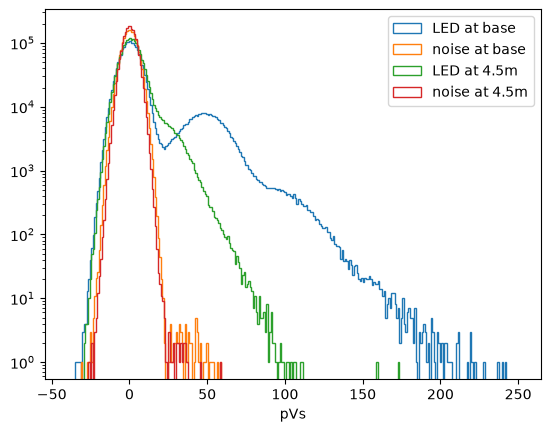

In [103]:
plt.hist(sum_waveform_LED_atbase, bins=np.linspace(-40, 250, 300), histtype='step', label='LED at base')
plt.hist(sum_waveform_noise_atbase, bins=np.linspace(-40, 250, 300), histtype='step', label='noise at base')
plt.hist(sum_waveform_LED_at4_5m, bins=np.linspace(-40, 250, 300), histtype='step', label='LED at 4.5m')
plt.hist(sum_waveform_noise_at4_5m, bins=np.linspace(-40, 250, 300), histtype='step', label='noise at 4.5m')

plt.legend()
plt.yscale('log')
plt.xlabel('pVs')
plt.show()


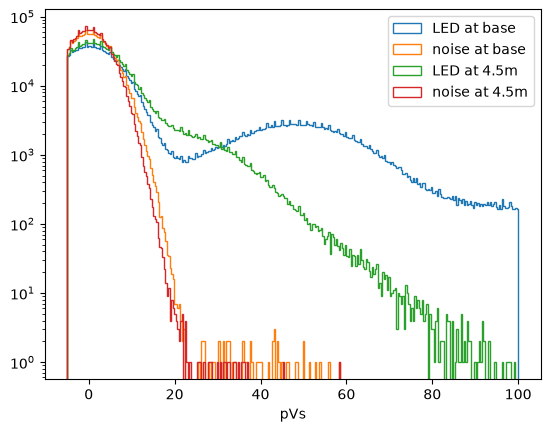

In [104]:
plt.hist(sum_waveform_LED_atbase, bins=np.linspace(-5, 100, 300), histtype='step', label='LED at base')
plt.hist(sum_waveform_noise_atbase, bins=np.linspace(-5, 100, 300), histtype='step', label='noise at base')
plt.hist(sum_waveform_LED_at4_5m, bins=np.linspace(-5, 100, 300), histtype='step', label='LED at 4.5m')
plt.hist(sum_waveform_noise_at4_5m, bins=np.linspace(-5, 100, 300), histtype='step', label='noise at 4.5m')

plt.legend()
plt.yscale('log')
plt.xlabel('pVs')
plt.show()


In [105]:
#fit the spectra
from spe_fit_funcs import fit_spe

mu = 46.620 ± 0.036
2*mu = 93.240, 3*mu = 139.861
sigmas = 14.731 ± 0.030, 19.271 ± 0.194, 31.713 ± 1.094
amplitudes = 11737.3 ± 29.2, 686.7 ± 7.3, 23.7 ± 1.6
pedestal = 162289.4 ± 154.7, sigma0 = 6.268 ± 0.004
chi2_red = 25.210 (4084.0 / 162)


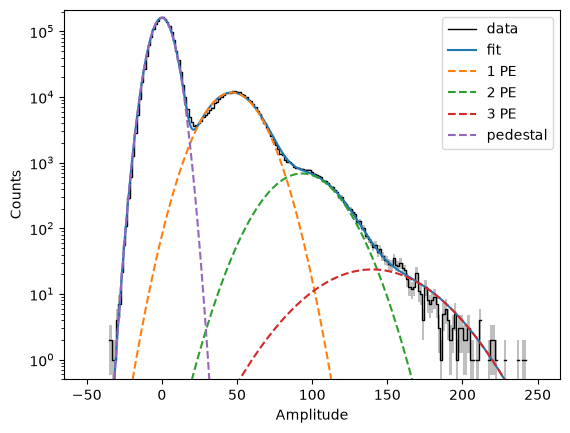

In [111]:
fit_values, fig, ax = fit_spe(
    sum_waveform_LED_atbase,
    n_gaussians=3,
    linear=False,
    plot=True,
    print_fit=True,
    fit_range=(-50, 250.0),
    mu_bounds=(40, 60),
    pedestal=True,
    shared_sigma=False,
)

mu = 46.637 ± 0.036
2*mu = 93.273, 3*mu = 139.910
sigmas = 14.730 ± 0.030, 18.839 ± 0.209, 23.291 ± 1.276
amplitudes = 11743.9 ± 29.2, 695.0 ± 7.6, 29.0 ± 2.2
pedestal = 162304.4 ± 154.8, sigma0 = 6.267 ± 0.004
slope = 0.00 ± 0.00, intercept = 1.2 ± 0.5
chi2_red = 25.160 (4025.6 / 160)


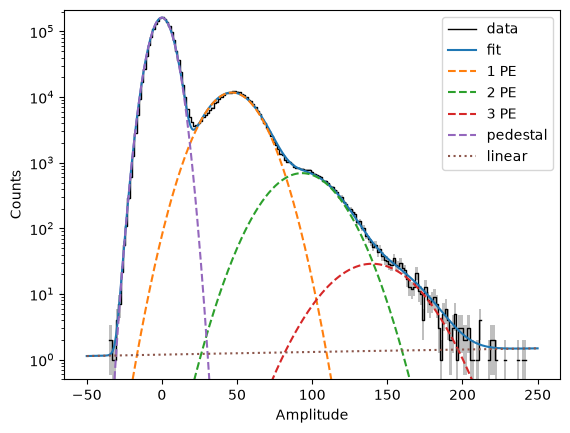

In [114]:
fit_values, fig, ax = fit_spe(
    sum_waveform_LED_atbase,
    n_gaussians=3,
    linear=True,
    plot=True,
    print_fit=True,
    fit_range=(-50, 250.0),
    mu_bounds=(40, 60),
    pedestal=True,
    shared_sigma=False,
)

mu = 20.000 ± 0.097
2*mu = 40.000
sigmas = 10.973 ± 0.067, 17.793 ± 0.269
amplitudes = 6702.9 ± 25.2, 192.8 ± 7.1
pedestal = 121111.3 ± 119.8, sigma0 = 6.009 ± 0.004
chi2_red = 109.461 (14011.0 / 128)


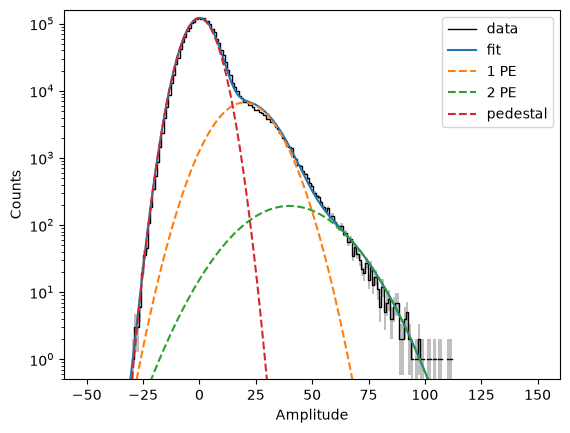

In [125]:
fit_values, fig, ax = fit_spe(
    sum_waveform_LED_at4_5m,
    n_gaussians=2,
    linear=False,
    plot=True,
    print_fit=True,
    fit_range=(-50, 150.0),
    mu_bounds=(20, 50),
    pedestal=True,
    shared_sigma=False,
)